In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Machine learning models
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import joblib
import os

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv
Saving validation.csv to validation.csv


In [ ]:
# Load datasets
train_df = pd.read_csv("train.csv")
validation_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")

# Display dataset dimensions
print("Training set:", train_df.shape)
print("Validation set:", validation_df.shape)
print("Testing set:", test_df.shape)

Training set: (12000, 26)
Validation set: (6000, 26)
Testing set: (2000, 26)


In [ ]:

# Identify target and excluded identifier
TARGET = "is_fraud"
ID_COLUMN = "transaction_id"

# Separate features and target
X_train = train_df.drop(columns=[TARGET, ID_COLUMN])
y_train = train_df[TARGET]

X_val = validation_df.drop(columns=[TARGET, ID_COLUMN])
y_val = validation_df[TARGET]

X_test = test_df.drop(columns=[TARGET, ID_COLUMN])
y_test = test_df[TARGET]

# Check dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

# Display fraud counts
print("\nFraud cases:")
print("Training:", y_train.sum())
print("Validation:", y_val.sum())
print("Testing:", y_test.sum())


Training features: (12000, 24)
Validation features: (6000, 24)
Testing features: (2000, 24)

Fraud cases:
Training: 203
Validation: 102
Testing: 34


In [ ]:

# Initialize majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")

# Train baseline
baseline_model.fit(X_train, y_train)

# Generate validation predictions
baseline_predictions = baseline_model.predict(X_val)

# Evaluate baseline
print("MAJORITY-CLASS BASELINE")
print("-----------------------")

print("Accuracy:", baseline_model.score(X_val, y_val))
print("Precision:", precision_score(y_val, baseline_predictions, zero_division=0))
print("Recall:", recall_score(y_val, baseline_predictions, zero_division=0))
print("F1-Score:", f1_score(y_val, baseline_predictions, zero_division=0))
print("PR-AUC:", average_precision_score(y_val, baseline_predictions))

# Confusion matrix
cm = confusion_matrix(y_val, baseline_predictions)
print("\nConfusion Matrix:")
print(cm)

MAJORITY-CLASS BASELINE
-----------------------
Accuracy: 0.983
Precision: 0.0
Recall: 0.0
F1-Score: 0.0
PR-AUC: 0.017

Confusion Matrix:
[[5898    0]
 [ 102    0]]


In [ ]:
# Calculate class imbalance weight using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraudulent transactions:", positive_count)
print("Scale positive weight:",  round(scale_pos_weight, 2))

Legitimate transactions: 11797
Fraudulent transactions: 203
Scale positive weight: 58.11


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify feature types
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total original features:", X_train.shape[1])

Categorical features: 5
Numerical features: 19
Total original features: 24


In [ ]:

# Preprocess training and validation data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Initialize XGBoost classifier
fraud_model = XGBClassifier(
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

# Train with early stopping
fraud_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=100
)

# Rebuild pipeline using the fitted preprocessing and model
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", fraud_model)
])

print("\nXGBoost training completed!")
print("Best iteration:", fraud_model.best_iteration)

[0]	validation_0-aucpr:0.07437
[100]	validation_0-aucpr:0.20338
[147]	validation_0-aucpr:0.18790

XGBoost training completed!
Best iteration: 97


In [ ]:

# Generate fraud probabilities on validation data
y_val_prob = fraud_model.predict_proba(X_val_processed)[:, 1]

# Find optimal classification threshold using F1
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_prob)

f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

# Calculate optimal threshold metrics
best_f1 = f1_scores[best_index]
best_precision = precisions[best_index]
best_recall = recalls[best_index]

# Calculate AUC metrics
val_pr_auc = average_precision_score(y_val, y_val_prob)
val_roc_auc = roc_auc_score(y_val, y_val_prob)

# Display results
print("VALIDATION EVALUATION RESULTS")
print("-----------------------------")
print(f"Best threshold:  {best_threshold:.4f}")
print(f"Best F1:         {best_f1:.4f}")
print(f"Precision:       {best_precision:.4f}")
print(f"Recall:          {best_recall:.4f}")
print(f"PR-AUC:          {val_pr_auc:.4f}")


VALIDATION EVALUATION RESULTS
-----------------------------
Best threshold:  0.6937
Best F1:         0.2815
Precision:       0.2262
Recall:          0.3725
PR-AUC:          0.2099


In [ ]:

# Generate fraud probabilities on test data
X_test_processed = preprocessor.transform(X_test)
y_test_prob = fraud_model.predict_proba(X_test_processed)[:, 1]

# Apply the threshold selected using validation data
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Calculate test metrics
print("FINAL TEST SET RESULTS")
print("----------------------")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_test_prob):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


FINAL TEST SET RESULTS
----------------------
Precision: 0.2464
Recall:    0.5000
F1 Score:  0.3301
PR-AUC:    0.2714
ROC-AUC:   0.9389

Confusion Matrix:
[[1914   52]
 [  17   17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1966
           1       0.25      0.50      0.33        34

    accuracy                           0.97      2000
   macro avg       0.62      0.74      0.66      2000
weighted avg       0.98      0.97      0.97      2000



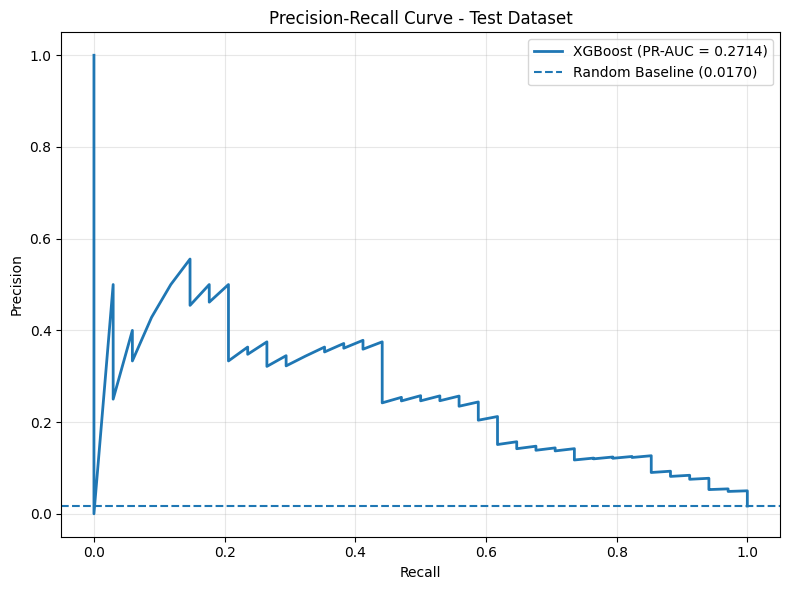

In [ ]:

# Calculate precision-recall curve
test_precisions, test_recalls, _ = precision_recall_curve(
    y_test, y_test_prob
)

# Calculate Average Precision (PR-AUC)
test_aucpr = average_precision_score(y_test, y_test_prob)

# Plot curve
plt.figure(figsize=(8, 6))

plt.plot(
    test_recalls,
    test_precisions,
    label=f"XGBoost (PR-AUC = {test_aucpr:.4f})",
    linewidth=2
)

# Random classifier baseline
plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"Random Baseline ({y_test.mean():.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Test Dataset")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
from google.colab import files

files.download("/content/fraud_xgboost_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Import our fraud model functions
from fraud_model import load_model, predict_fraud

# Load the saved model
model_bundle = load_model(
    "/content/fraud_xgboost_model.joblib"
)

print("Model loaded successfully!")

# Test predictions on 5 test transactions
sample_transactions = X_test.head(5)

results = predict_fraud(
    sample_transactions,
    model_bundle
)

# Display results
print(results[
    ["fraud_probability", "predicted_class", "fraud_status"]
])

ModuleNotFoundError: No module named 'fraud_model'

In [ ]:
# Select 5 actual fraudulent transactions from test data
fraud_indices = y_test[y_test == 1].index[:5]

fraud_samples = X_test.loc[fraud_indices]

# Run predictions
fraud_results = predict_fraud(
    fraud_samples,
    model_bundlecla
)

# Display actual and predicted results
fraud_results["actual_class"] = y_test.loc[fraud_indices]

print(fraud_results[
    ["actual_class", "fraud_probability",
     "predicted_class", "fraud_status"]
])

      actual_class  fraud_probability  predicted_class fraud_status
1324             1           0.995623                1        Fraud
1476             1           0.994703                1        Fraud
1628             1           0.995862                1        Fraud
1678             1           0.995623                1        Fraud
1777             1           0.995623                1        Fraud
